TASK-3

cell 1:Extract and clean country information

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("data/netflix_cleaned.csv")
print("Unknown countries:", (df["country"] == "Unknown").sum())

known = df[df["country"] != "Unknown"]
print(len(known), "titles with a known country")
print(known["country"].nunique(), "different countries")

Unknown countries: 287
8500 titles with a known country
85 different countries


cell 2:calculate content count by country 

In [12]:
country_counts = known["country"].value_counts()
country_counts.head(10)

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64

cell 3:Identify top content producing countries

In [13]:
top10 = country_counts.head(10)
share = (top10 / len(known) * 100).round(1)
print(share)
print("Top 10 share:", round(top10.sum() / len(known) * 100, 1), "%")

country
United States     38.1
India             12.4
United Kingdom     7.5
Pakistan           4.9
Canada             3.2
Japan              3.0
South Korea        2.5
France             2.5
Spain              2.1
Mexico             1.6
Name: count, dtype: float64
Top 10 share: 78.0 %


cell 4:create charts and rankings

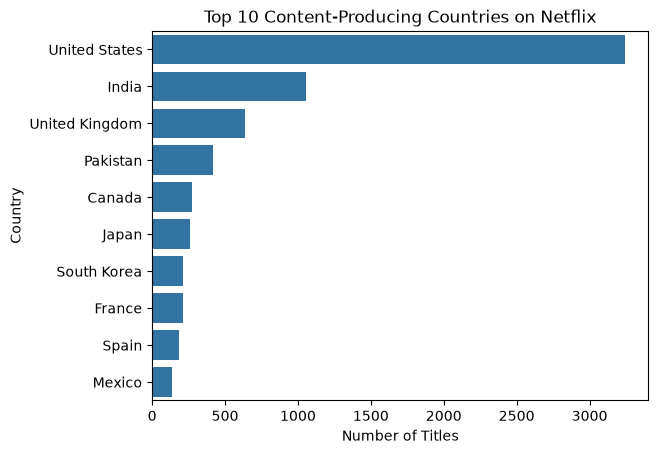

In [14]:
sns.barplot(x=top10.values, y=top10.index)
plt.title("Top 10 Content-Producing Countries on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

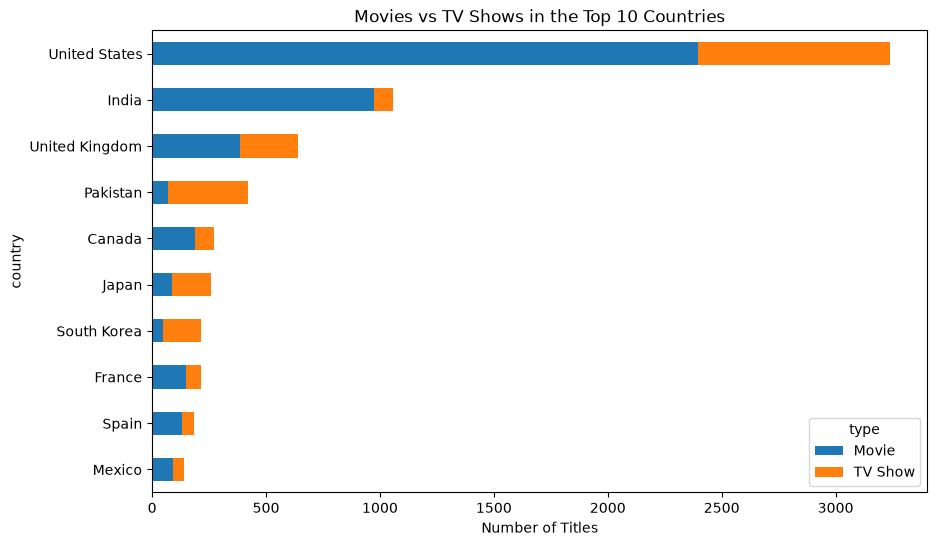

In [15]:
type_by_country = pd.crosstab(known["country"], known["type"]).loc[top10.index]
type_by_country.plot(kind="barh", stacked=True, figsize=(10, 6))
plt.title("Movies vs TV Shows in the Top 10 Countries")
plt.xlabel("Number of Titles")
plt.gca().invert_yaxis()
plt.show()

In [16]:
tv_pct = (type_by_country["TV Show"] / type_by_country.sum(axis=1) * 100).round(1)
print(tv_pct.sort_values(ascending=False))

country
Pakistan          83.1
South Korea       77.1
Japan             66.4
United Kingdom    39.3
Mexico            34.8
Canada            31.0
France            30.5
Spain             29.1
United States     26.1
India              7.7
dtype: float64


cell 5:Business Insights

1.The unites states has the most titles with 3240 which is 38.1% of the catalog with a known country. 
2.India is secured with 1056 so the US has about 3 times as many.
3.This suggests that netflix catalog still depends heavily on American content and the platform may need more local content to attract viewers in other countries.
4.Pakisthan (83.1%),south korea (77.1%) and Japan (66.4%) have mostly TV Shows, while India has only 7.7% TV Shows,so its content is mostly movies.
5.This suggests that netflix may focus pn local series in some countries,since series keep viewers subscribed for longer,while India's content reflects its strong movie industry.
6.The top 10 countries make up 78.0% of all titles with a known country.
7.This means the content is concentrated in a few countries,even though 85 countries appear in the data.
8.287 titles have an unknown country and 18 countries have only one title.
9.This means some content can't be analyzes by region and many countries are barely represented so netflix may have room to grow in those markets.

conclusion: Netflix catalog is global in range but concentrated in a few countries led by the US and India.
countries like South Korea,Japan and Pakisthan stand out for TV shows which suggest that local series could be a growth area foe netflix.
